let $A$ and $B$ be two loci - below, a recombinant chromatid = chromatid with visible CO between $A$ and $B$, and a nonrecombinant chromatid = chromatid without visible CO in $A-B$. let $v$ be P(visible recombination event) between $A$ and $B$:

In [1]:
v = var('v')
v

v

## "absolute" drive

let $q$ be the proportion of recovered chromatids that are recombinant, then $1-q$ is the proportion of nonrecombinant chromatids recovered:

In [2]:
q = var('q')
q

q

let $r_{\text{abs}}$ be RF between $A$ and $B$, and $r^*_{\text{abs}}$ the RF between $A$ and $B$ in case of drive.

In [3]:
r_abs = var('r_abs')
r_star_abs = var('r_star_abs')
r_abs, r_star_abs

(r_abs, r_star_abs)

then $r_\text{abs} = \dfrac{1}{2}v$ and $r^*_\text{abs} = qv$:

<!-- $$
r^*_\text{abs} = \dfrac{(1/2)q}{(1/2)q + (1/2)(1-q)}v
$$ -->

In [4]:
r_abs = (1/2)*v
# r_star_abs = ((1/2)*q / ((1/2)*q + (1/2)*(1-q)))*v
r_star_abs = q*v
r_abs, r_star_abs

(1/2*v, q*v)

then $r^*_{\text{abs}} / r_{\text{abs}}$ in terms of $q$ becomes:

In [5]:
r_star_abs / r_abs

2*q

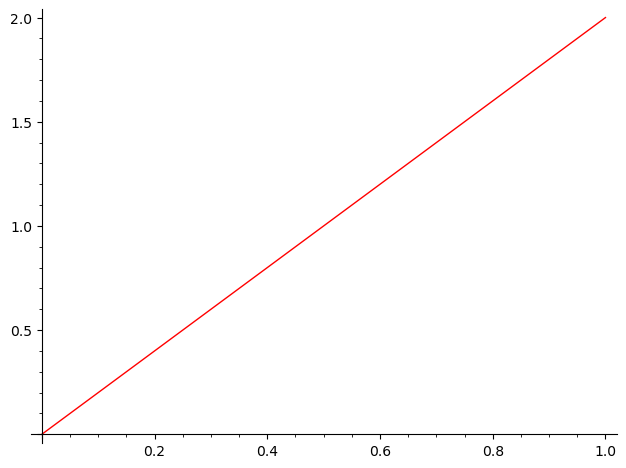

In [6]:
plot(r_star_abs / r_abs, xmin=0, xmax=1, color="#ff0000")

- RF under drive is always $2q$ times greater than RF without drive, independent of the actual probability of visible COs?

## "relative" drive

let $p$ be the percent increase in likelihood of recovering recombinant, compared to a nonrecombinant. EXAMPLE: $1 + p = 1.1$ represents a 10% increase in the likelihood of recovering a recombinant compared to a nonrecombinant:

In [7]:
p = var('p')
p

p

then

$$
r = (1/2)v
$$

and

$$
r^* = \dfrac{(1/2)(1 + p)}{(1/2)(1 + p) + (1/2)}v
$$

In [8]:
r = (1/2)*v
r_star = ( ((1/2)*(1+p))/((1/2)*(1+p) + (1/2)) ) * v
r, r_star

(1/2*v, (p + 1)*v/(p + 2))

then $r^* / r$ in terms of $p$ becomes:

In [9]:
r_star / r

2*(p + 1)/(p + 2)

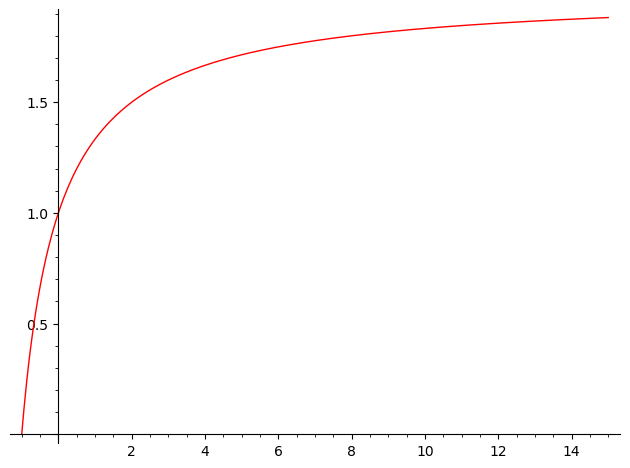

In [10]:
plot(r_star / r, xmin=-1, xmax=15, ymin=0, color="#ff0000")

- the increase in RF is logarithmic(?) in $p$, and caps out at 2 (even when the chance of recovering a recombinant chromatid is multiple times higher, the RF difference is still only 2x?)
- a negative $p$ (anti-drive) leads to a slightly smaller reduction than $p$

## map functions under drive

we know from haldane's map function that the RF for a given cM can be given by

$$
r = \dfrac{1-e^{-2d}}{2}
$$

where $d$ is the cM:

In [11]:
d = var('d')
haldane = (1 - exp(-2 * d)) / 2
d, haldane

(d, -1/2*e^(-2*d) + 1/2)

then can't we get a map function for drive, just by multiplying in $r^* / r$? for example, in the "absolute" drive formulation, where $r^*/r = 2q$, we can multiply that in:

In [12]:
rf = haldane * (r_star_abs / r_abs)
rf

-q*(e^(-2*d) - 1)

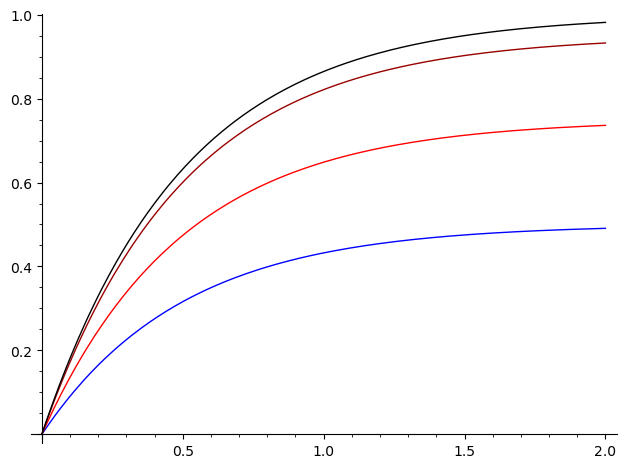

In [13]:
q_onehalf = plot(rf.subs(q=0.5), xmin=0, xmax=2)
q_threequarters = plot(rf.subs(q=0.75), xmin=0, xmax=2, color="#ff0000")
q_ninetyfive = plot(rf.subs(q=0.95), xmin=0, xmax=2, color="#990000")
q_full = plot(rf.subs(q=1), xmin=0, xmax=2, color="#000000")
q_onehalf + q_threequarters + q_ninetyfive + q_full

in the "relative drive" formulation, where $r^* / r = 2\dfrac{p+1}{p
+2}$:

In [14]:
rf = haldane * (r_star / r)
rf

-(p + 1)*(e^(-2*d) - 1)/(p + 2)

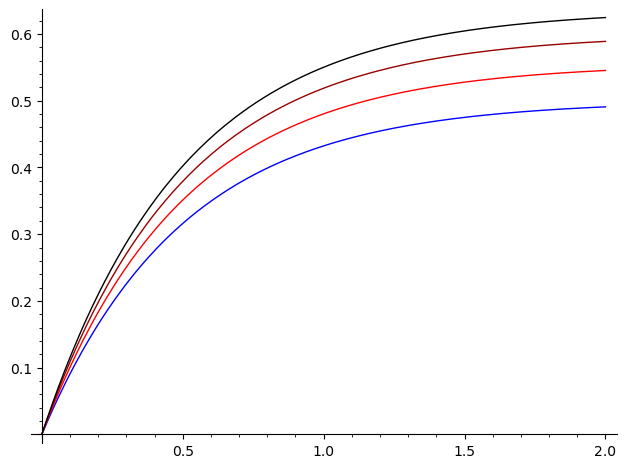

In [15]:
p_zero = plot(rf.subs(p=0), xmin=0, xmax=2, color="#0000ff")
p_plus25 = plot(rf.subs(p=0.25), xmin=0, xmax=2, color="#ff0000")
p_plus50 = plot(rf.subs(p=0.5), xmin=0, xmax=2, color="#990000")
p_plus75 = plot(rf.subs(p=0.75), xmin=0, xmax=2, color="#000000")
p_zero + p_plus25 + p_plus50 + p_plus75

## distance from centromere

let's say "chromosome-wide", $p = 0.5$ (50% increase), but this isn't uniformly distributed (higher drive near centromere). represent chromosome as $[0, 1]$, centromere at $0$.

let $p$ as a density(?) be a function of distance from centromere $x$, exponentially distributed:

In [16]:
from sage.symbolic.integration.integral import definite_integral, indefinite_integral

In [17]:
x = var('x')
C = var('C')
p_density_with_constant = C*exp(-x)
C_soln = solve(definite_integral(p_density_with_constant,x,0,1) == 0.5, C)[0].rhs()
p_density = p_density_with_constant.subs(C=C_soln)

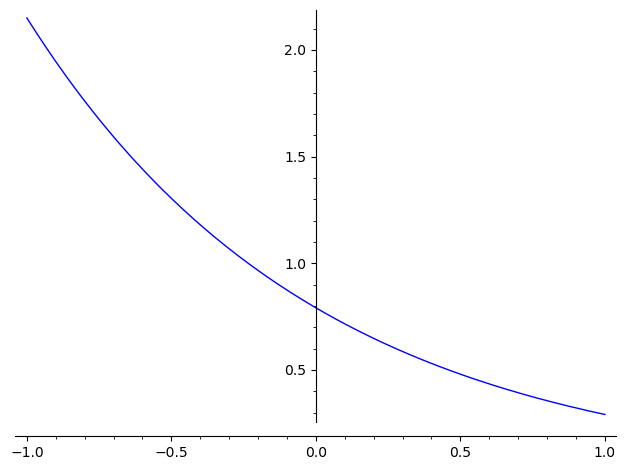

In [18]:
plot(p_density)

In [19]:
rf_ratio_wrt_centromere_dist = (r_star / r).subs(p=indefinite_integral(p_density, x))
rf_ratio_wrt_centromere_dist

2*(e^(-x + 1)/(e - 1) - 2)/(e^(-x + 1)/(e - 1) - 4)

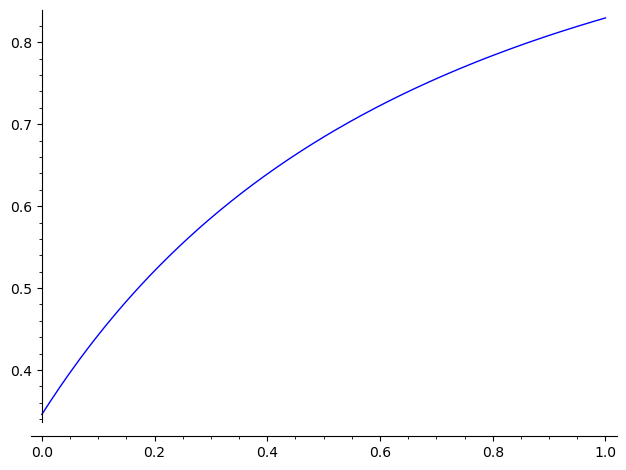

In [20]:
plot(rf_ratio_wrt_centromere_dist, xmin=0, xmax=1)